# 4.1 - Model: Naive Bayes (stemmed variant)

**Training and evaluation of the Naive Bayes classifier on the stemmed variant of the TF-IDF data.**

## Theoretical Foundation

Naive Bayes is a probabilistic classifier based on Bayes' theorem:

`P(class | text) ∝ P(text | class) × P(class)`

The probability that a text belongs to a particular class is proportional to the probability that we would obtain that text if we knew the class, multiplied by the prior probability of that class.

The "naive" part comes from the assumption that all features (terms in the vocabulary) are conditionally independent of one another, i.e. that the presence of one word does not affect the probability of the presence of another when we already know whether the review is positive or negative.
This assumption is almost certainly incorrect in practice (words in natural language are interdependent), but the classifier still performs well on textual data despite this simplification - a well-known and well-documented phenomenon in the literature.

We use the `MultinomialNB` variant - it models features as if they come from a multinomial distribution, which naturally fits non-negative, frequency-like values - exactly what TF-IDF produces.

## Processing Flow:

1. We load the previously prepared stemmed TF-IDF data using the `load_variant()` function

2. We create a `MultinomialNB` classifier and define the `alpha` hyperparameter values that `GridSearchCV` will examine

3. We call the shared `train_and_evaluate()` function:
    1. GridSearchCV on the TRAIN set:
        - examines all combinations of hyperparameters from the param_grid
        - uses k-fold cross-validation (5 folds by default)
        - selects the hyperparameter combination that gives the best F1 score
    2. Final model:
        - after selecting the best hyperparameters, GridSearchCV trains the best model on the entire TRAIN set
    3. Evaluation:
        - the best model is used on the TEST set for the first time
        - accuracy, precision, recall, and F1 are calculated, and a confusion matrix is created
    4. Saving the results


In [1]:
import sys
sys.path.append("..")

from src.data_io import load_variant
from src.modeling import train_and_evaluate

from sklearn.naive_bayes import MultinomialNB

## Loading the Data

We load the stemmed variant (TF-IDF matrices + labels), saved in `3_vectorization.ipynb`.


In [2]:
X_train, X_test, y_train, y_test = load_variant("stemmed")

print(f"Train: {X_train.shape}")
print(f"Test:  {X_test.shape}")

Train: (39665, 66682)
Test:  (9917, 66682)


## Model and Hyperparameters

The only important hyperparameter of `MultinomialNB` is `alpha` - the Laplace (Lidstone) smoothing parameter.

Why smoothing is necessary:
- If a term has never appeared in the training examples of one class, the classical (unsmoothed) estimate would assign it a probability of exactly 0 for that class
- Since the Bayesian formula multiplies the probabilities of all terms in a review, a single zero would cancel out the entire product - regardless of how convincing the remaining terms are
- Smoothing adds a small constant (`alpha`) to every count, preventing zero probabilities

Smaller `alpha` (close to 0) - less smoothing, the model relies more on the exact counts from the training set, but is more sensitive to rare/random patterns (risk of overfitting).

Larger `alpha` - more smoothing, a more conservative estimate, but it can "dilute" the actual signal if it is too strong.


In [3]:
model = MultinomialNB()

param_grid = {"alpha": [0.01, 0.05, 0.075, 0.1, 0.125, 0.15, 0.175, 0.2, 0.225, 0.25, 0.275, 0.3, 0.5, 1.0]}

## Training and Evaluation

Calls `train_and_evaluate()` from `src/modeling.py`.

The function tests all specified `alpha` values using 5-fold GridSearchCV on the training set, selects the one with the best F1 score, then trains the best model on the entire training set and evaluates it on the test set.

The results are saved as the model, metrics, and confusion matrix.


========== naive_bayes (stem) ==========
Best parameters: {'alpha': 0.125}
GridSearchCV time: 8.4s

Accuracy  : 0.8830
Precision : 0.8759
Recall    : 0.8935
F1        : 0.8846


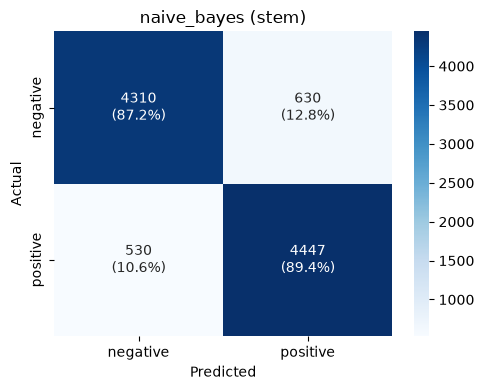


Saved:
  ..\models\naive_bayes_stem.joblib
  ..\results\metrics\naive_bayes_stem.json
  ..\results\figures\naive_bayes_stem_confusion_matrix.png


In [4]:
metrics = train_and_evaluate(
    model=model,
    param_grid=param_grid,
    X_train=X_train,
    y_train=y_train,
    X_test=X_test,
    y_test=y_test,
    model_name="naive_bayes",
    variant="stem",
)

## Conclusions

- Best `alpha`: 0.125

- Results:
    - Accuracy  : 0.8830
    - Precision : 0.8759
    - Recall    : 0.8935
    - F1        : 0.8846

- The model shows similar performance for both classes (positive and negative): it correctly identifies 87.2% of negative and 89.4% of positive reviews.

- The model somewhat more frequently classifies negative reviews as positive, i.e. it makes false positive errors more often (12.8%).
